# `blog_agent` walkthrough

This notebook tours the `blog_agent` package, which combines `blog_writing_agent_v3_research_finetuned_claude_mod` and `blog_analysis_agent_v1` into one callable agent. You'll:

1. Look at the package layout and settings
2. See how nodes call models
3. Build and draw the graph
4. Run the **analysis** pipeline **one node at a time**, inspecting state after each step
5. Run the **technical** pipeline end to end with `write_blog()`
6. Read the QA output
7. Resume a failed run from a checkpoint
8. Try the other ways to call the agent, and learn how to extend it

### The `LIVE` switch

| `LIVE` | What happens | Cost |
|---|---|---|
| `True` | Real Claude models and Tavily search | About $0.50 for the whole notebook (one analysis piece, one technical post) |
| `False` | The fake models and fake search from `tests/fakes.py`. Every cell still runs, but outputs are placeholders | Free |

With `LIVE = False`, files go to a temp folder, not `blog_posts/` and `runs/`. Section 7 (resume) always uses fakes, so it's free in both modes.

In [8]:
LIVE = True   # True = real models and search (costs money); False = offline fakes (free)

import sys, json, tempfile
from pathlib import Path

sys.path.insert(0, str(Path("tests").resolve()))   # tests/fakes.py, for offline mode and section 7
from IPython.display import Markdown, Image, display

## 1. Package layout

```
blog_agent/
  config.py              Settings: model per role, folders, concurrency, retries, prices
  llm.py                 Models: the only place that talks to Claude (stop_reason checks, fallbacks)
  schemas.py             Pydantic: evidence, the two plan shapes, edit/grounding results, BlogResult
  profiles.py            Per-kind prompts for the shared nodes (router, research, tagger)
  state.py               The graph State and Deps (settings + models + search)
  research.py            Tavily search (parallel) and the research node
  nodes.py               Shared nodes: classify, router, tagger, save
  pipelines/technical.py orchestrator -> [worker x N] -> reducer -> grounding
  pipelines/analysis.py  planner -> writer -> editor
  graph.py               build_graph(): wires everything together
  qa.py                  Per-node JSON snapshots, draft versions, diffs
  checkpoint.py          sqlite_checkpointer(): resumable runs
  api.py                 write_blog() and as_tool()
  cli.py                 python -m blog_agent ...
```

**One design rule matters most:** nodes never create a `ChatAnthropic` or call Tavily directly. They get a `deps` object holding `settings`, `models` and `search`. That's why the same graph runs with real models or with fakes. This notebook relies on that rule, and so do the tests.

## 2. Settings

`Settings.from_env()` loads `.env` and applies any `BLOG_AGENT_*` overrides, e.g. `BLOG_AGENT_EDITOR_MODEL`, `BLOG_AGENT_WRITER_MAX_TOKENS`, `BLOG_AGENT_ROUTER_EFFORT`. Settings are frozen. To change something in code, use `with_overrides()`, which returns a new copy.

In [9]:
from blog_agent import Settings, ModelSpec

settings = Settings.from_env()
if LIVE:
    settings.check_credentials()   # fails fast if ANTHROPIC_API_KEY / TAVILY_API_KEY are missing
else:
    tmp = Path(tempfile.mkdtemp(prefix="blog_agent_walkthrough_"))
    settings = settings.with_overrides(output_dir=tmp / "posts", qa_dir=tmp / "runs")

print(f"{'role':<11} {'model':<20} {'max_tokens':>10}  effort")
for role, spec in settings.models.items():
    print(f"{role:<11} {spec.model:<20} {spec.max_tokens:>10}  {spec.effort or 'model default'}")
print()
print("output_dir:", settings.output_dir)
print("qa_dir:    ", settings.qa_dir)
print("max_concurrency:", settings.max_concurrency, "| grounding_check:", settings.grounding_check,
      "| refusal_fallbacks:", settings.refusal_fallbacks)

role        model                max_tokens  effort
classifier  claude-haiku-5-5           2048  model default
router      claude-haiku-5-5           2048  low
research    claude-haiku-5-5           8192  model default
planner     claude-sonnet-5-5          8192  model default
writer      claude-sonnet-5-5         16000  model default
editor      claude-opus-5-5           16000  model default
tagger      claude-haiku-5-5           2048  model default

output_dir: D:\Agentic-AI-Learning\Blogger-Agent\blog_posts
qa_dir:     D:\Agentic-AI-Learning\Blogger-Agent\runs
max_concurrency: 3 | grounding_check: True | refusal_fallbacks: True


In [10]:
# Overrides return a new Settings; the original is unchanged. (Shown only, not used below.)
cheaper = settings.with_overrides(
    grounding_check=False,
    models={**settings.models, "editor": ModelSpec("claude-sonnet-5-5", 16000)},
)
print("editor in `cheaper`: ", cheaper.models["editor"].model)
print("editor in `settings`:", settings.models["editor"].model)

editor in `cheaper`:  claude-sonnet-5-5
editor in `settings`: claude-opus-5-5


## 3. How nodes call models: `Models` and `Deps`

`Models` has two methods. Nodes name a **role**, not a model:

- `models.structured(role, Schema, messages)` returns a validated Pydantic object. If the response was cut off (`max_tokens`), refused, or can't be parsed, it raises `LLMError` instead of returning a partial object.
- `models.text(role, messages)` returns `(text, response_metadata)`. The caller decides what a bad `stop_reason` means. For example, the technical worker retries the section.

`Deps` bundles settings, models and search. It's built once and handed to every node.

In [11]:
from langchain_core.messages import HumanMessage
from blog_agent.llm import Models
from blog_agent.research import tavily_search
from blog_agent.schemas import KindDecision
from blog_agent.state import Deps

if LIVE:
    models, search = Models(settings), tavily_search
else:
    from fakes import FakeModels, fake_search
    models, search = FakeModels(), fake_search

deps = Deps(settings=settings, models=models, search=search)

decision = deps.models.structured(
    "classifier", KindDecision,
    [HumanMessage(content="Request: How do I tune Postgres autovacuum for a write-heavy table?")],
)
decision

KindDecision(kind='technical', reason='The request asks for concrete configuration steps to tune Postgres autovacuum settings, which is a technical how-to task.')

## 4. The graph

`build_graph()` wires a shared front (`classify → router → research`), then two writing branches, then a shared tail (`tagger → save`). The branch is chosen by `state["kind"]`.

The technical branch fans out with `Send`: one `worker` per outline section, running in parallel and capped by `max_concurrency`.

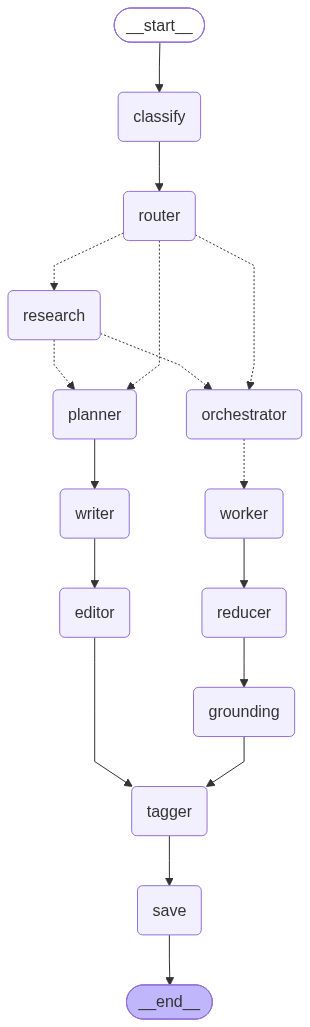

In [12]:
from blog_agent import build_graph

app = build_graph(settings, models=deps.models, search=deps.search)
try:
    display(Image(app.get_graph().draw_mermaid_png()))   # rendered via mermaid.ink (needs internet)
except Exception as e:
    print(f"(could not render PNG: {e})\n")
    print(app.get_graph().draw_mermaid())

## 5. The analysis pipeline, one node at a time

`write_blog()` streams the whole graph. Here we call each node function ourselves, so you can see exactly what it adds to the state.

Every node has the form `node(state, *, deps) -> dict`. It returns **only the keys it changes**, and LangGraph merges them into the state. Most keys are overwritten. A few lists (`sections`, `section_issues`, `warnings`) are **appended to** instead, because several nodes can write them, including parallel workers. The `step()` helper below does the same merge.

In [13]:
from blog_agent.nodes import classify_node, router_node, tagger_node, front_matter
from blog_agent.research import research_node
from blog_agent.pipelines import analysis

APPENDED = {"sections", "section_issues", "warnings"}   # keys with an operator.add reducer in State

def step(state, node_fn):
    update = node_fn(state, deps=deps)
    for k, v in update.items():
        state[k] = state.get(k, []) + v if k in APPENDED else v
    print(f"{node_fn.__name__} updated: {sorted(update)}")
    return update

state = {
    "topic": "Short piece: why do Indian sitcoms rarely get a second season on streaming platforms?",
    "kind": "auto",          # let the classifier decide
    "target_words": 500,
    "warnings": [],
}

### 5.1 `classify`
Resolves `kind="auto"` with a cheap Haiku call. An explicit `"technical"` or `"analysis"` skips the call. It also fills in `as_of` and `run_id` if they're missing, which is what lets the graph run from LangGraph Studio with just a topic.

In [14]:
step(state, classify_node)
print("kind:", state["kind"], "| as_of:", state["as_of"], "| run_id:", state["run_id"])

classify_node updated: ['as_of', 'kind', 'run_id']
kind: analysis | as_of: 2026-10-14 | run_id: 20261014-111337_short_piece_why_do_indian_sitcoms_rarely_get_a


### 5.2 `router`
Uses the **per-kind prompt** from `profiles.py` and decides between `closed_book` (no research), `hybrid` and `open_book` (recent news). If it needs research, it also writes the search queries.

In [15]:
step(state, router_node)
print("mode:", state["mode"], "| needs_research:", state["needs_research"], "| recency_days:", state["recency_days"])
for q in state["queries"]:
    print("  -", q)

router_node updated: ['mode', 'needs_research', 'queries', 'recency_days']
mode: hybrid | needs_research: True | recency_days: 365
  - Indian sitcoms cancelled after one season streaming platforms reasons
  - Indian web series renewal rates Netflix Prime Video Hotstar second season data
  - creators and showrunners interview why Indian comedy series are not renewed
  - Indian streaming comedy successes multiple seasons Panchayat Gullak Mismatched renewal
  - Indian OTT platform business model content budgets viewership metrics renewals 2025 2026
  - critics analysis Indian sitcom format decline streaming originals writers' room


### 5.3 `research`
1. Runs the queries **in parallel** on Tavily. `open_book` uses `topic="news"` and `time_range="week"`, so results come back with dates.
2. Drops blocked domains in code (Wikipedia, social media...) before the LLM sees anything.
3. Haiku turns the raw results into clean `EvidenceItem`s.
4. Keeps **only URLs that search actually returned**, so the model can't invent a source.
5. Stores the raw Tavily text in `raw_sources`. The editor and grounding check use it later to verify claims.

A failed query adds a warning instead of crashing the run.

In [16]:
if state["needs_research"]:
    step(state, research_node)
for i, e in enumerate(state.get("evidence", []), 1):
    print(f"[{i}] {e.title[:70]}\n    {e.url} | {e.published_at or 'date unknown'}")
print("\nwarnings:", state["warnings"] or "none")

research_node updated: ['evidence', 'raw_sources', 'warnings']
[1] 22 TV shows that were canceled after a single season - Stacker Stories
    https://stacker.com/stories/tv/22-tv-shows-were-canceled-after-single-season | date unknown
[2] Canceled After One Season: 26 of The Best TV Shows That Didn't Last
    https://www.hollywoodreporter.com/lists/best-tv-shows-canceled-after-one-season | date unknown
[3] Renewed and Canceled TV Shows 2026 | Rotten Tomatoes
    https://editorial.rottentomatoes.com/article/renewed-and-cancelled-tv-shows-2026 | date unknown
[4] Renewed and Canceled TV Shows in 2023
    https://www.thewrap.com/renewed-canceled-tv-shows-2023 | date unknown
[5] How India's Streaming Wars Benefit Screenwriters
    https://www.hollywoodreporter.com/movies/movie-news/how-indias-streaming-wars-benefit-screenwriters-1169361 | date unknown
[6] India OTT Market Size, Share & 2031 Growth Trends Report
    https://www.mordorintelligence.com/industry-reports/india-ott-market | date u

### 5.4 `planner` (analysis branch)
Sonnet plans the piece as an **argument**: a thesis, 3–6 beats and a counterpoint. Each beat lists the evidence numbers it relies on, and code removes any number that doesn't exist.

In [17]:
step(state, analysis.planner_node)
plan = state["plan"]
print("TITLE: ", plan.title)
print("THESIS:", plan.thesis)
print("KIND:  ", plan.piece_kind, "| TARGET:", plan.target_words, "words\n")
for b in plan.beats:
    print(f"{b.id}. {b.point}\n   evidence: {b.evidence_ids or 'reasoning only'}")
print("\nCOUNTERPOINT:", plan.counterpoint)

planner_node updated: ['plan']
TITLE:  Why Indian streaming sitcoms struggle to come back for a second season
THESIS: Indian sitcoms rarely get a second season because streaming's economics favour finite, exportable, event-style series over the open-ended, habit-building comedy a sitcom needs, and the platforms that could nurture one have little reason to wait.
KIND:   analysis | TARGET: 500 words

1. Streaming in India was built on a model of finite, pre-planned seasons, which suits thrillers and dramas better than sitcoms.
   evidence: [5]
2. Platforms are under pressure to turn viewing into subscription and ad revenue, so they back titles that sell the service fast, and comedy is a slow burn.
   evidence: [6, 7, 5]
3. This is partly a global streaming pattern: one-season cancellations are common everywhere, and Indian comedy gets no special shelter from them.
   evidence: [1, 2, 3]
4. The Indian sitcom's natural habitat was never the streamer; it thrived on broadcast TV and is now d

### 5.5 `writer`
One Sonnet call drafts the whole piece, so the argument and voice stay consistent. If the response was cut off or refused, the node raises instead of passing a broken draft on.

In [18]:
from blog_agent.utils import prose_word_count

step(state, analysis.writer_node)
print(prose_word_count(state["draft"]), "words\n")
display(Markdown(state["draft"][:1500] + ("\n\n*…(truncated)*" if len(state["draft"]) > 1500 else "")))

writer_node updated: ['description', 'draft', 'title']
584 words



The sense that Indian sitcoms vanish after one season on streaming is widely shared. It is also unmeasured: no dataset I could find tracks Indian sitcom renewals, so what follows reasons from incentives, not a count. The argument is that streaming's economics favour finite, exportable, event-style series over the open-ended, habit-building comedy a sitcom needs, and the platforms that could nurture one have little reason to wait.

## Built for closed arcs

US streamers [brought the writers' room to Bollywood](https://www.hollywoodreporter.com/movies/movie-news/how-indias-streaming-wars-benefit-screenwriters-1169361), and with it a template: streaming series tend to have a fixed number of episodes and seasons with pre-planned story arcs. That suits a thriller, which has a mystery to solve and an ending to reach.

A sitcom's value lies elsewhere. It comes from repetition, familiar rooms and running jokes that pay off over years. Sold as eight episodes with a closed arc, a sitcom is undersold from the start.

## A slow burn on a fast clock

The pressure on platforms is commercial. India's OTT market is [projected to grow from $11.05 billion in 2026 to $22.18 billion by 2031](https://www.mordorintelligence.com/industry-reports/india-ott-market), and the same report calls the central issue converting viewing time into sustainable subscription and advertising income. Subscribers are arriving fast: one cited estimate puts [paid subscribers at 148.2 million](https://www.linkedin.com/

*…(truncated)*

### 5.6 `editor`
Opus reviews the draft against the plan **and the raw source text**, lists what it fixed, and returns the revised piece. Code then checks the word count and runs one length pass if it's more than ±10% off target. If the editor fails, the unedited draft is kept and a warning is added, so the run doesn't fail.

In [19]:
step(state, analysis.editor_node)
print("FINAL TITLE:", state["title"])
print("FINAL WORDS:", prose_word_count(state["final"]), "\n")
for issue in state["editor_issues"]:
    print("  -", issue)

editor_node updated: ['editor_issues', 'editor_revision', 'final', 'plan', 'title', 'warnings']
FINAL TITLE: Why Indian streaming sitcoms struggle to come back for a second season
FINAL WORDS: 555 

  - Draft ran about 620 words against a 500 target. Cut throat-clearing such as 'The argument is that...' and the repeated 'fit' caveats, and tightened every section to about 540 words.
  - 'Subscribers are arriving fast' was backed by 148.2 million paid subscribers, which is a total, not a growth rate. Reframed it as the size of the base and attributed the figure to Ormax via the LinkedIn post. Also softened 'rising fast' in the counterpoint to 'as subscriptions grow'.
  - 'Sold as eight episodes' added a specific episode count that no source supports. Changed it to 'a short, closed run'.
  - The Breathe overseas share came from one show but was used to prove that thrillers travel. Added that one show proves little, so the point now reads as a hint about platform incentives.
  - The Rotten

In [20]:
from blog_agent.qa import write_diff

# The same sentence-level diff the QA folder gets: draft -> editor revision
diff_path = Path(tempfile.mkdtemp()) / "d.diff"
write_diff(diff_path, state["draft"], state["editor_revision"], "draft", "editor_revision")
print(diff_path.read_text(encoding="utf-8")[:3000])

--- draft
+++ editor_revision
@@ -1,56 +1,58 @@
-The sense that Indian sitcoms vanish after one season on streaming is widely shared.
-It is also unmeasured: no dataset I could find tracks Indian sitcom renewals, so what follows reasons from incentives, not a count.
-The argument is that streaming's economics favour finite, exportable, event-style series over the open-ended, habit-building comedy a sitcom needs, and the platforms that could nurture one have little reason to wait.
+The sense that Indian sitcoms vanish after one season on streaming is widely held.
+It is also unmeasured.
+No dataset I could find tracks Indian sitcom renewals, so this piece reasons from incentives, not a count.
+The case is simple: streaming's economics favour finite, exportable, event-style series over the open-ended, habit-building comedy a sitcom needs.
+And the platforms that could nurture one have little reason to wait.
 
 ## Built for closed arcs
 
-US streamers [brought the writers' room to Bollywo

### 5.7 `tagger`, then a preview of `save`
Haiku proposes tags, and code normalizes them, removes duplicates, drops generic ones (`opinion`, `culture`...) and caps the count at 8. `save` writes the front matter plus the post. Here we only preview it, so this hand-run piece isn't saved.

In [21]:
step(state, tagger_node)
print(front_matter(state) + state["final"][:400] + "…")

tagger_node updated: ['tags']
---
title: "Why Indian streaming sitcoms struggle to come back for a second season"
date: 2026-10-14
kind: analysis
piece_kind: analysis
description: "Indian sitcoms rarely get a second season because streaming's economics favour finite, exportable, event-style series over the open-ended, habit-building comedy a sitcom needs, and the platforms that could nurture one have little reason to wait."
tags: [indian-sitcoms, streaming-economics, indian-ott-market, netflix, amazon-prime-video, scripted-vs-unscripted-tv, comedy-renewals]
---

# Why Indian streaming sitcoms struggle to come back for a second season

The sense that Indian sitcoms vanish after one season on streaming is widely held. It is also unmeasured. No dataset I could find tracks Indian sitcom renewals, so this piece reasons from incentives, not a count. The case is simple: streaming's economics favour finite, exportable, event-style series over the open-ended, habi…


## 6. The technical pipeline, end to end with `write_blog()`

Normally you just call `write_blog()`. It builds the graph, streams it, writes QA snapshots, tracks token usage and returns a `BlogResult`.

Technical flow: **orchestrator** (Sonnet outline of 5–9 sections) → **workers** (one per section, in parallel; each section's code is checked and retried once if broken) → **reducer** (joins sections in order) → **grounding** (Opus checks cited claims against sources and returns small find/replace fixes, which code applies only if safe) → tagger → save.

In [22]:
from blog_agent import write_blog
from blog_agent.cli import _summary

result = write_blog(
    "Explainer: when to use LangGraph Send fan-out versus a plain loop, with a short Python example",
    kind="technical",
    settings=settings,
    models=None if LIVE else deps.models,   # None = real models built from settings
    search=None if LIVE else deps.search,
)
print(_summary(result))

KIND: technical | MODE: hybrid | EVIDENCE: 15
TITLE: LangGraph Send Fan-Out vs. a Plain Loop: How to Choose
DESCRIPTION: A practical explainer on when LangGraph's Send API for dynamic fan-out beats a simple Python loop, with a short runnable example, failure modes, and debugging tips.
TAGS: ['langgraph', 'send-api', 'fan-out', 'map-reduce', 'python']
EDITOR_ISSUES: 12
  - Source text does not mention debugging/visualization complexity; it does support runtime task creation.
  - Graph API source text lacks the superstep claim; AI Practitioner supports it.
  - Graph API source text doesn't state this; MortalApps does.
  - Source text only shows the conditional-edge example, not the 'not known ahead of time' wording.
  - Claim supported by AI Practitioner source text, not Graph API source text.
  - Cited source text does not mention debugging/visualization complexity.
  - Cited source text supports runtime task creation but not the debugging claim.
  - Cited source text does not mention d

In [23]:
# BlogResult is a Pydantic model: easy to log, return from an API, or dump to JSON
print(list(result.model_dump().keys()))
print()
print("sections:", [t["title"] for t in result.plan["tasks"]])
print("usage per model:", json.dumps(result.usage, indent=1)[:600])

['run_id', 'kind', 'mode', 'title', 'description', 'markdown', 'tags', 'output_path', 'qa_dir', 'evidence', 'editor_issues', 'section_issues', 'warnings', 'usage', 'estimated_cost_usd', 'plan']

sections: ['The decision in one minute', 'How Send fan-out works under the hood', 'When a plain loop is the better answer', 'When Send fan-out earns its complexity', 'Minimal example: the same job as a loop and as Send', 'Failure modes and edge cases', 'Debugging, observability, and cost', 'Summary: a practical rubric']
usage per model: {
 "claude-haiku-5-5": {
  "total_tokens": 21229,
  "input_tokens": 18992,
  "output_tokens": 2237
 },
 "claude-sonnet-5-5": {
  "total_tokens": 44979,
  "input_tokens": 31026,
  "output_tokens": 13953
 },
 "claude-opus-5-5": {
  "input_tokens": 17469,
  "output_tokens": 3825,
  "total_tokens": 21294
 }
}


## 7. Reading the QA output

Each run gets `runs/<run_id>/`:

| File | Use it to… |
|---|---|
| `NN_<node>.json` | See exactly what one node changed (`update`) and the full state after it (`state_after`). Parallel workers are `05_worker_task01.json`, `05_worker_task02.json`, … |
| `v1_draft.md`, `v2_editor_revision.md`, `v3_final.md` | Read the versions side by side |
| `diff_1_draft_to_editor.diff` | Review what the editor or grounding check changed, sentence by sentence |
| `final_state.json` | Inspect everything at the end |
| `error.txt` | Only present when a run crashed: the traceback |

In [24]:
qa = Path(result.qa_dir)
for p in sorted(qa.iterdir()):
    print(f"{p.name:<36} {p.stat().st_size:>8,} bytes")

00_input.json                             416 bytes
01_classify.json                          471 bytes
02_router.json                          1,245 bytes
03_research.json                       51,261 bytes
04_orchestrator.json                   46,915 bytes
05_worker_task01.json                  61,212 bytes
05_worker_task02.json                  62,985 bytes
05_worker_task03.json                  62,433 bytes
05_worker_task04.json                  62,690 bytes
05_worker_task05.json                  63,240 bytes
05_worker_task06.json                  62,866 bytes
05_worker_task07.json                  61,839 bytes
05_worker_task08.json                  61,063 bytes
06_reducer.json                       195,629 bytes
07_grounding.json                     174,361 bytes
08_tagger.json                        128,530 bytes
09_save.json                          128,689 bytes
diff_1_draft_to_editor.diff             7,566 bytes
diff_2_editor_to_final.diff                14 bytes
final_state.

In [25]:
grounding = json.loads(next(qa.glob("*_grounding.json")).read_text(encoding="utf-8"))
print("grounding check fixes:", grounding["update"].get("editor_issues") or "none needed")
print()
print((qa / "diff_1_draft_to_editor.diff").read_text(encoding="utf-8")[:2500])

grounding check fixes: ['Source text does not mention debugging/visualization complexity; it does support runtime task creation.', 'Graph API source text lacks the superstep claim; AI Practitioner supports it.', "Graph API source text doesn't state this; MortalApps does.", "Source text only shows the conditional-edge example, not the 'not known ahead of time' wording.", 'Claim supported by AI Practitioner source text, not Graph API source text.', 'Cited source text does not mention debugging/visualization complexity.', 'Cited source text supports runtime task creation but not the debugging claim.', 'Cited source text does not mention debugging/visualization complexity.', "Graph API source text doesn't state this; MortalApps does.", 'Superstep grouping is described in AI Practitioner source text, not Graph API source text.', 'Cited source text does not mention debugging/visualization complexity.', 'Evidence shows a reported issue and fixes, not documented behavior changes across release

In [26]:
print(Path(result.output_path).read_text(encoding="utf-8")[:900])

---
title: "LangGraph Send Fan-Out vs. a Plain Loop: How to Choose"
date: 2026-10-14
kind: technical
blog_kind: explainer
description: "A practical explainer on when LangGraph's Send API for dynamic fan-out beats a simple Python loop, with a short runnable example, failure modes, and debugging tips."
tags: [langgraph, send-api, fan-out, map-reduce, python]
---

# LangGraph Send Fan-Out vs. a Plain Loop: How to Choose

## The decision in one minute

**The trade-off:** Send gives you parallel branches whose count is decided at runtime, each with its own input state. A loop gives you simplicity and sequential control. Send creates parallel tasks at runtime, with their number determined by graph state rather than fixed at design time ([Source](https://aipractitioner.substack.com/p/scaling-langgraph-agents-parallelization)). The state you send can differ from the core graph state ([Source](ht


## 8. Resuming a failed run (free; always uses fakes)

With a checkpointer, LangGraph saves the state after every step. If a run crashes (network error, rate limit, a bug in one node), you can continue it with `resume_run_id`. Finished nodes aren't repeated, and the expensive planning and writing calls aren't paid for twice.

Use `sqlite_checkpointer()` rather than a bare `SqliteSaver`. Checkpoints store our Pydantic types (evidence, plans), and the helper registers them with the serializer. Without that, LangGraph warns when loading them and says a future version will refuse to load them.

Below, a fake tagger fails on its first call. The run crashes, then resumes from the checkpoint.

In [27]:
from blog_agent import sqlite_checkpointer
from fakes import FakeModels, fake_search
from blog_agent.schemas import BlogTags

calls = {"tagger": 0}
def flaky_tagger():
    calls["tagger"] += 1
    if calls["tagger"] == 1:
        raise ConnectionError("simulated network blip in the tagger")
    return BlogTags(tags=["resumed-run", "checkpointing"])

fake = FakeModels({"BlogTags": flaky_tagger})
demo_dir = Path(tempfile.mkdtemp(prefix="resume_demo_"))
demo_settings = settings.with_overrides(output_dir=demo_dir / "posts", qa_dir=demo_dir / "runs")

with sqlite_checkpointer(demo_dir / "checkpoints.sqlite") as cp:
    try:
        write_blog("Resume demo", "analysis", settings=demo_settings, models=fake, search=fake_search, checkpointer=cp)
    except ConnectionError as e:
        run_id = next((demo_dir / "runs").iterdir()).name
        print(f"crashed: {e}\nrun_id: {run_id}\n")

    planner_calls_before = sum(c[1] == "AnalysisPlan" for c in fake.calls)
    resumed = write_blog("", settings=demo_settings, models=fake, search=fake_search,
                         checkpointer=cp, resume_run_id=run_id)

print("resumed tags:", resumed.tags)
print("planner calls before/after resume:", planner_calls_before, "/",
      sum(c[1] == "AnalysisPlan" for c in fake.calls), "(planner not re-run)")

crashed: simulated network blip in the tagger
run_id: 20261014-111725_resume_demo

resumed tags: ['resumed-run', 'checkpointing']
planner calls before/after resume: 1 / 1 (planner not re-run)


From the command line it's the same idea:

```bash
python -m blog_agent "your topic" --checkpoint-db runs/checkpoints.sqlite
# ...crash...
python -m blog_agent --resume <run_id> --checkpoint-db runs/checkpoints.sqlite
```

## 9. Other ways to call the agent

| From | How |
|---|---|
| Python | `write_blog(topic, kind="auto" \| "technical" \| "analysis", target_words=..., save=..., qa=...)` |
| Terminal | `python -m blog_agent "topic" --kind analysis --words 800 -v` (`--help` for all flags; `--json` for machine-readable output) |
| Another agent | `as_tool()` returns a LangChain tool (below). Bind it with `llm.bind_tools([tool])` or pass it to `create_agent` |
| LangGraph Studio | `langgraph dev` in the project root (needs `langgraph-cli[inmem]`). It reads `langgraph.json` and loads `blog_agent/studio.py`. Input: `{"topic": "...", "kind": "auto"}` |

In [21]:
from blog_agent import as_tool

tool = as_tool(settings)
print("name:", tool.name)
print("description:", tool.description)
print("args:", json.dumps(tool.args, indent=1))

name: write_blog_post
description: Research and write a complete blog post on a topic and save it as Markdown. kind: 'technical' for engineering/AI/dev topics, 'analysis' for media/culture/business opinion pieces, or 'auto'. Returns the title, saved file path and tags. Takes a few minutes.
args: {
 "topic": {
  "title": "Topic",
  "type": "string"
 },
 "kind": {
  "default": "auto",
  "enum": [
   "auto",
   "technical",
   "analysis"
  ],
  "title": "Kind",
  "type": "string"
 },
 "target_words": {
  "anyOf": [
   {
    "type": "integer"
   },
   {
    "type": "null"
   }
  ],
  "default": null,
  "title": "Target Words"
 }
}


## 10. Tests

`tests/` runs both pipelines end to end with fakes, plus the failure paths (search down, editor fails, open-book date filter, resume). It takes about 2 seconds and costs nothing. Run it after any change to a prompt, node or schema.

In [22]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], capture_output=True, text=True).stdout[-600:])

..................                                                       [100%]
18 passed in 9.01s



## 11. Extending the package

**Change a prompt.** Router, research and tagger prompts are in `profiles.py`, one set per kind. Planner, writer, worker, editor and grounding prompts sit at the top of `pipelines/technical.py` and `pipelines/analysis.py`.

**Change a model.** No code change needed: set `BLOG_AGENT_<ROLE>_MODEL` in `.env`, or pass `settings.with_overrides(models={...})`. For a new model, also add its price to `PRICES` in `config.py` so the cost estimate stays complete.

**Add a third kind** (e.g. a `"newsletter"` digest):
1. `schemas.py`: add it to `Kind`, plus a plan schema if it needs its own shape.
2. `profiles.py`: add a `Profile` with its router, research and tagger prompts, and register it in `PROFILES`.
3. `pipelines/newsletter.py`: write its nodes. Each must end by setting `title`, `description`, `draft`, `editor_revision` and `final`, because tagger, save and QA read those keys.
4. `graph.py`: add the nodes, make `to_pipeline()` in `nodes.py` route to the first one, and connect the last one to `tagger`.
5. `nodes.py`: describe the new kind in `CLASSIFY_SYSTEM` so `kind="auto"` can pick it.
6. Add a test in `tests/test_graph.py` with a fake for the new plan schema.

**Add a node to an existing branch** (e.g. a plan-approval step): write `def my_node(state, *, deps) -> dict`, register it with `g.add_node("my_node", node(my_node))`, and rewire the edges around it. Return only the keys you change.